# CNN + LSTM + CTC: completed IAM training

**Final status: early-stopped at epoch 17 of the requested maximum 20.** The selected checkpoint is **epoch 14**, validation **CER 10.07%** and **WER 34.29%**. Epochs 15-17 did not improve the CER-first selection score; epochs 18-20 were not run.

This run used all 6,482 IAM training lines and the same saved 100 validation lines selected by the teammate. No test images/labels or optional preprocessing treatments were evaluated. Bentham preparation and diagnostic results are historical; full training was IAM only.

See the [complete research report](../../docs/CNN_LSTM_CTC.md), [final summary](../../results/cnn_lstm_ctc/training/20261114_baseline/iam/FINAL_SUMMARY.md), and [100 epoch 14 examples](../../results/cnn_lstm_ctc/training/20261114_baseline/iam/examples/epoch_014_random_100_seed5112.md). This notebook displays recorded results and leaves the training launcher disabled.


In [1]:
from pathlib import Path
import sys
import json

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/training/ctc_training.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython.display import display, Image
from src.training.ctc_training import TrainingConfig, train_dataset
from src.models.cnn_lstm_ctc import CNNLSTMCTCRecognizer

PREPARATION = ROOT / "results/cnn_lstm_ctc/data_preparation/20261114T211708884735Z"
RUN_ROOT = ROOT / "results/cnn_lstm_ctc/training/20261114_baseline"
DATASETS = ("iam",)
CONFIG = TrainingConfig(epochs=20, batch_size=4, patience=3, cpu_threads=4, device="cpu")


## Read final status

Rerun this cell to read saved state. Training has finished; `status.json` reports `early_stopped`. `progress.json` retains the last batch and does not alone indicate a running process. Epoch-boundary resume preserves completed work, but this run's early-stopping counter is already exhausted.


In [2]:
import csv
scope_path = RUN_ROOT / "dataset_selection_request.json"
if scope_path.exists():
    scope = json.loads(scope_path.read_text(encoding="utf-8"))
    print("Dataset scope:", scope["datasets"], "| requested maximum:", scope["epochs"])
    print("Supervisor state:", scope["state"])

for name in DATASETS:
    run = RUN_ROOT / name
    print(f"\n{name.upper()}")
    if not (run / "status.json").exists():
        print("No saved status.")
        continue
    status = json.loads((run / "status.json").read_text(encoding="utf-8"))
    print("Status:", status["status"], "| completed epochs:", status.get("completed_epochs", 0),
          "| maximum requested:", status.get("requested_epochs"))
    if status["status"] == "training" and (run / "progress.json").exists():
        progress = json.loads((run / "progress.json").read_text(encoding="utf-8"))
        print(f"Epoch {progress['epoch']}: {progress['seen']:,}/{progress['training_count']:,} images")
        print(f"Estimated minutes left in current epoch: {progress['estimated_remaining_epoch_seconds']/60:.1f}")
    if (run / "history.csv").exists():
        with (run / "history.csv").open(encoding="utf-8", newline="") as stream:
            history = list(csv.DictReader(stream))
        best = min(history, key=lambda row: (float(row["validation_cer"]),
                   float(row["validation_wer"]), float(row["validation_loss"])))
        print(f"Selected epoch: {best['epoch']}; validation CER: {100*float(best['validation_cer']):.2f}%; "
              f"WER: {100*float(best['validation_wer']):.2f}%")


Dataset scope: ['iam'] | requested maximum: 20
Supervisor state: finished_iam_only

IAM
Status: early_stopped | completed epochs: 17 | maximum requested: 20
Selected epoch: 14; validation CER: 10.07%; WER: 34.29%


## Training/validation graphs and epoch table

Training loss averages losses observed while weights were changing during the epoch. Validation loss is measured with frozen weights afterward. CER/WER are corpus-level validation rates, not averages of per-line errors. Lower is better, but loss improvements alone do not guarantee readable predictions. Empty early predictions can produce 100% CER/WER.

These graphs show completed epochs only. No synthetic points or final-test scores are added.



IAM


,epoch,train_loss,validation_loss,validation_cer,validation_wer,train_count,validation_count,training_seconds,validation_seconds,optimizer_steps
0,1,3.231300,3.131089,0.972845,0.988248,6482,100,1732.157428,4.407104,1621
1,2,2.651510,2.147680,0.605341,0.913462,6482,100,5610.964976,4.611417,3242
2,3,1.598183,1.121866,0.323376,0.714744,6482,100,1376.859422,5.141891,4863
3,4,1.028051,0.790660,0.233084,0.620726,6482,100,1250.329174,4.805839,6484
4,5,0.774521,0.625754,0.177642,0.522436,6482,100,1232.368492,4.712512,8105
5,6,0.632217,0.530547,0.153428,0.478632,6482,100,1248.108825,4.619977,9726
6,7,0.534799,0.500667,0.145734,0.450855,6482,100,1245.295559,4.476699,11347
7,8,0.467543,0.454436,0.125820,0.415598,6482,100,1260.412118,4.377099,12968
8,9,0.416087,0.463874,0.129667,0.415598,6482,100,1228.429572,4.535194,14589
9,10,0.375599,0.414588,0.117674,0.386752,6482,100,1284.575358,4.306341,16210


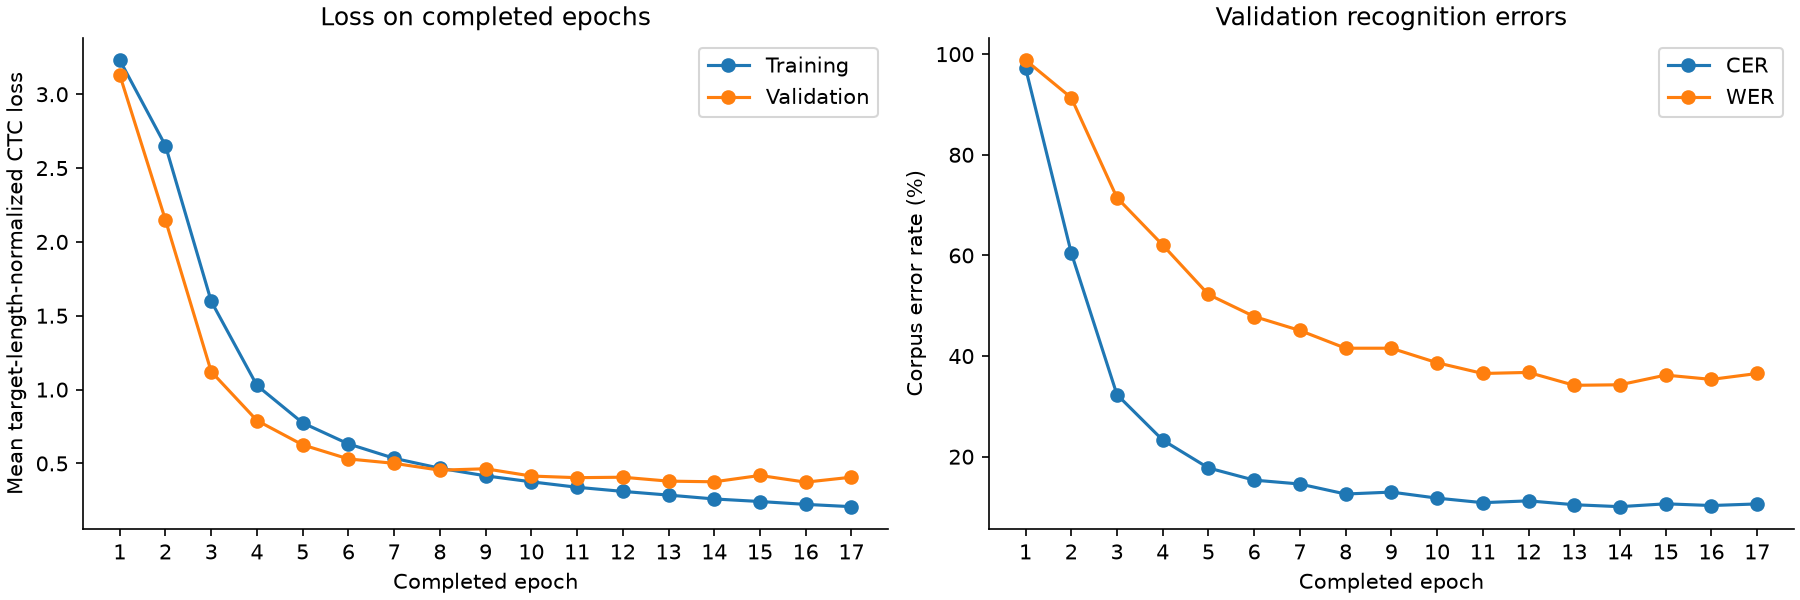

In [3]:
import pandas as pd
for name in DATASETS:
    run = RUN_ROOT / name
    print(f"\n{name.upper()}")
    if (run / "history.csv").is_file():
        display(pd.read_csv(run / "history.csv"))
        display(Image(filename=str(run / "training_curves.png")))
    else:
        print("No completed epoch yet. Rerun this cell after an epoch finishes.")


## Documented results for all 17 completed epochs

[EPOCH_RESULTS.md](../../results/cnn_lstm_ctc/training/20261114_baseline/iam/EPOCH_RESULTS.md) and `epoch_summary.csv` contain loss, corpus CER/WER, changes in percentage points, exact-line/empty-output counts, elapsed time, and fixed actual-versus-predicted text examples. Scores were verified against all 1,700 saved predictions; these are repeated assessments of the same 100 validation lines.

Epoch 14 has the best CER; epoch 13 has the lowest WER and epoch 16 the lowest validation loss. Epochs 18-20 have no results because early stopping occurred at 17. Available weights are archived for epochs 2-17; epoch 1's scores/predictions remain but its old weights are unavailable. The 100-example export is the same complete validation set shuffled, not new data. See [FINAL_VERIFICATION.json](../../results/cnn_lstm_ctc/training/20261114_baseline/iam/FINAL_VERIFICATION.json) for the final artifact checks.


In [4]:
summary_path = RUN_ROOT / "iam" / "epoch_summary.csv"
if summary_path.is_file():
    epoch_summary = pd.read_csv(summary_path)
    display(epoch_summary[["epoch", "train_loss", "validation_loss", "validation_cer_pct",
                           "validation_wer_pct", "cer_change_vs_previous_pp",
                           "wer_change_vs_previous_pp", "exact_text_lines", "empty_predictions"]])
    print("Full report:", RUN_ROOT / "iam" / "EPOCH_RESULTS.md")
else:
    print("The report observer will create the epoch summary when completed results are available.")


Full report: C:\Users\chirayu ubale\OneDrive\Desktop\Research Project\results\cnn_lstm_ctc\training\20261114_baseline\iam\EPOCH_RESULTS.md


,epoch,train_loss,validation_loss,validation_cer_pct,validation_wer_pct,cer_change_vs_previous_pp,wer_change_vs_previous_pp,exact_text_lines,empty_predictions
0,1,3.231300,3.131089,97.284453,98.824786,NaN,NaN,0,0
1,2,2.651510,2.147680,60.534057,91.346154,-36.750396,-7.478632,0,0
2,3,1.598183,1.121866,32.337633,71.474359,-28.196425,-19.871795,0,0
3,4,1.028051,0.790660,23.308441,62.072650,-9.029192,-9.401709,0,0
4,5,0.774521,0.625754,17.764200,52.243590,-5.544241,-9.829060,2,0
5,6,0.632217,0.530547,15.342838,47.863248,-2.421362,-4.380342,2,0
6,7,0.534799,0.500667,14.573433,45.085470,-0.769405,-2.777778,4,0
7,8,0.467543,0.454436,12.582032,41.559829,-1.991401,-3.525641,7,0
8,9,0.416087,0.463874,12.966735,41.559829,0.384702,0.000000,5,0
9,10,0.375599,0.414588,11.767368,38.675214,-1.199366,-2.884615,10,0


## Training launcher (disabled)

Leave `RUN_TRAINING=False` to inspect completed results. This run's `last.pt` has early-stopping counter 3, so increasing only the epoch limit does not resume epoch 18. Changing patience changes the protected training identity. Any deliberate continuation needs a separately documented policy/run preserving its parent checkpoint; none is launched here.

For a fresh independent reproduction, select a new output folder. For a run interrupted before stopping, matching data/model/software/settings and saved optimizer/RNG/shuffle state support epoch-boundary resume; unfinished partial epochs repeat. Only the maximum epoch limit can change in place. Do not start simultaneous writers to one run folder.


In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    for name in DATASETS:
        run = RUN_ROOT / name
        if (run / "status.json").is_file():
            status = json.loads((run / "status.json").read_text(encoding="utf-8"))
            if status["status"] == "training":
                raise RuntimeError("A run is marked active. Confirm it has stopped before starting another writer.")
        result = train_dataset(name, run, CONFIG, preparation_dir=PREPARATION,
                               resume=(run / "metadata.json").exists())
        print(name, result)
else:
    print("Training launch disabled; this run has finished. Saved status, reports and graphs are safe to inspect.")


Training launch disabled; this run has finished. Saved status, reports and graphs are safe to inspect.


## Load the selected trained checkpoint

`best.pt` is selected epoch 14; `last.pt` is completed epoch 17. Loading restores vocabulary, mandatory image preparation, weights, and checkpoint provenance. Use the selected checkpoint for later frozen-model preprocessing comparisons. The following example is not executed automatically:

```python
recognizer = CNNLSTMCTCRecognizer.from_checkpoint(RUN_ROOT / "iam" / "best.pt", device="cpu")
# prediction = recognizer.predict(a_pillow_line_image)
# configuration = recognizer.to_config()  # includes checkpoint SHA-256 and epoch
```

Checkpoint files are binary and Git-ignored. Preserve them separately. The next research task is validation-only preprocessing selection, followed by final evaluation on the teammate's same 250 IAM test lines after the protocol is fixed.
